# Final Mini-Project

## Learning Latent Text Representations for Document Clustering and Topic Discovery

## 研究问题

文本表示方式如何影响文档聚类与主题发现？

## 数据集

使用 20 Newsgroups 的四类别子集：
- comp.graphics
- sci.space
- alt.atheism
- talk.religion.misc

去除 headers、footers、quotes，并删除空白文本。
所有实验使用相同的文档及顺序。

## 实验方案

1. TF-IDF → K-means。
2. Sentence Transformer embeddings → K-means。
3. TF-IDF → AE → 潜在表示 → K-means。
4. 二值词袋 → VAE → 后验均值 → K-means。
5. 词频矩阵 → 10 主题 LDA。
6. 比较不同表示的二维可视化。

## 统一设置

- 随机种子：42。
- K-means 簇数：4。
- 聚类评价：ARI、NMI、Silhouette score。
- 真实类别不参与无监督模型训练。
- 保留文档原始索引，检查各表示的样本对应关系。

本项目首先在整个文档集合上学习无监督表示并进行比较。
所得指标描述当前文档集合上的聚类结果，
不作为独立测试集上的泛化性能。

## 实验记录

记录表示维度、模型参数、随机种子、
神经网络训练损失、聚类评价及结果观察。

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

RANDOM_SEED = 42
N_CLUSTERS = 4

categories = [
    "comp.graphics",
    "sci.space",
    "alt.atheism",
    "talk.religion.misc",
]

newsgroups = fetch_20newsgroups(
    subset="all",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_SEED,
)

text_df = pd.DataFrame({
    "text": newsgroups.data,
    "label": newsgroups.target,
})

label_to_category = dict(enumerate(newsgroups.target_names))
text_df["category"] = text_df["label"].map(label_to_category)

empty_mask = text_df["text"].str.strip().eq("")

clean_text_df = (
    text_df.loc[~empty_mask]
    .copy()
    .reset_index(names="original_index")
)

documents = clean_text_df["text"].tolist()
true_labels = clean_text_df["label"].to_numpy()
document_ids = clean_text_df["original_index"].to_numpy()

assert len(documents) == len(true_labels) == len(document_ids)
assert clean_text_df["original_index"].is_unique
assert all(document.strip() for document in documents)

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())
print("\nOriginal document count:", len(text_df))
print("Removed empty documents:", int(empty_mask.sum()))
print("Remaining document count:", len(documents))

print("\nDocuments per category:")
print(clean_text_df["category"].value_counts().sort_index())

print("\nFirst 5 document IDs:", document_ids[:5])

Python executable: /opt/anaconda3/bin/python
Working directory: /Users/cheeseowl/Desktop/科研/final_project

Original document count: 3387
Removed empty documents: 92
Remaining document count: 3295

Documents per category:
category
alt.atheism           779
comp.graphics         955
sci.space             955
talk.religion.misc    606
Name: count, dtype: int64

First 5 document IDs: [0 1 2 3 4]


## 1. TF-IDF 聚类基线

### 文本表示

使用 TfidfVectorizer：
- 转换为小写。
- 去除内置英文停用词。
- min_df=2。
- max_df=0.95。
- 最多保留 5000 个词项。
- 使用逐行 L2 归一化。
- 使用 float32 存储。

检查并记录全零向量数量，暂不删除文档，
确保各实验使用相同的文档与顺序。

### 聚类设置

- K-means 簇数：4。
- 初始化方法：k-means++。
- 初始化运行次数：20。
- 每次运行的最大迭代次数：300。
- 算法：lloyd。
- 随机种子：42。

### 评价设置

- ARI、NMI：使用全部文档。
- Silhouette：使用欧氏距离，在固定随机种子下抽取 2000 篇文档计算。
- 真实类别仅用于计算 ARI 和 NMI，不参与聚类训练。

后续各表示在 K-means 前统一进行逐行 L2 归一化，
全零向量保持为零，并使用相同的聚类与评价设置。

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    max_features=5000,
    norm="l2",
    dtype=np.float32,
)

X_tfidf = tfidf_vectorizer.fit_transform(documents)
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

tfidf_zero_mask = X_tfidf.getnnz(axis=1) == 0

row_norms = np.sqrt(
    np.asarray(X_tfidf.multiply(X_tfidf).sum(axis=1)).ravel()
)

assert X_tfidf.shape[0] == len(document_ids)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_feature_names))
print("Data type:", X_tfidf.dtype)
print("Zero-vector documents:", int(tfidf_zero_mask.sum()))
print("First 5 row norms:", row_norms[:5])

TF-IDF matrix shape: (3295, 5000)
Vocabulary size: 5000
Data type: float32
Zero-vector documents: 15
First 5 row norms: [0.99999994 1.         1.         1.         1.        ]


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from threadpoolctl import threadpool_limits


def evaluate_clustering(X, y_true, cluster_labels):
    return {
        "ARI": adjusted_rand_score(y_true, cluster_labels),
        "NMI": normalized_mutual_info_score(
            y_true,
            cluster_labels,
            average_method="arithmetic",
        ),
        "Silhouette": silhouette_score(
            X,
            cluster_labels,
            metric="euclidean",
            sample_size=min(2000, X.shape[0]),
            random_state=RANDOM_SEED,
        ),
    }


kmeans_tfidf = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=20,
    max_iter=300,
    algorithm="lloyd",
    random_state=RANDOM_SEED,
)

print("Training TF-IDF K-means...")

with threadpool_limits(limits=1):
    clusters_tfidf = kmeans_tfidf.fit_predict(X_tfidf)

    tfidf_metrics = evaluate_clustering(
        X_tfidf,
        true_labels,
        clusters_tfidf,
    )

tfidf_result = {
    "Representation": "TF-IDF",
    "Dimension": X_tfidf.shape[1],
    **tfidf_metrics,
}

clustering_results = {"TF-IDF": tfidf_result}

display(pd.DataFrame(list(clustering_results.values())).round(4))

print("\nDocuments per cluster:")
print(pd.Series(clusters_tfidf).value_counts().sort_index())

print("\nIterations in selected run:", kmeans_tfidf.n_iter_)

Training TF-IDF K-means...


,Representation,Dimension,ARI,NMI,Silhouette
0,TF-IDF,5000,0.1765,0.3602,0.005



Documents per cluster:
0    1942
1     406
2     659
3     288
Name: count, dtype: int64

Iterations in selected run: 22


### TF-IDF 基线结果

- 文档数量：3295。
- 表示维度：5000。
- 全零向量：15 篇，保留在实验中。
- ARI：约 0.1765。
- NMI：约 0.3602。
- 抽样 Silhouette：约 0.0050。
- 选中运行的迭代次数：22。

四个簇分别包含 1942、406、659、288 篇文档。
最大簇约占全部文档的 59%。

聚类与真实类别存在一定对应，但当前表示空间中的簇分离程度较弱。
ARI、NMI 均不能解释为分类准确率。

需要结合各簇关键词及真实类别分布，
检查哪些内容被聚到一起。

In [4]:
category_cluster_table = pd.crosstab(
    clean_text_df["category"],
    pd.Series(clusters_tfidf, name="Cluster"),
)

print("True categories versus predicted clusters:")
display(category_cluster_table)

cluster_word_rows = []

for cluster_id in range(N_CLUSTERS):
    cluster_mask = clusters_tfidf == cluster_id

    mean_tfidf = np.asarray(
        X_tfidf[cluster_mask].mean(axis=0)
    ).ravel()

    top_indices = mean_tfidf.argsort()[-10:][::-1]

    cluster_word_rows.append({
        "Cluster": cluster_id,
        "Documents": int(cluster_mask.sum()),
        "Zero vectors": int(
            np.sum(cluster_mask & tfidf_zero_mask)
        ),
        "Top words": ", ".join(
            tfidf_feature_names[top_indices]
        ),
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(cluster_word_rows))

True categories versus predicted clusters:


Cluster,0,1,2,3
category,,,,
alt.atheism,620,3,5,151
comp.graphics,315,10,630,0
sci.space,539,393,22,1
talk.religion.misc,468,0,2,136


,Cluster,Documents,Zero vectors,Top words
0,0,1942,15,"just, don, think, people, like, know, does, time, say, ve"
1,1,406,0,"space, nasa, shuttle, moon, launch, orbit, mission, earth, like, satellite"
2,2,659,0,"graphics, thanks, image, file, files, format, program, know, ftp, help"
3,3,288,0,"god, jesus, bible, believe, people, faith, christian, say, belief, don"


### TF-IDF 基线的簇解释

| 簇 | 关键词与类别分布 | 解释 |
|---|---|---|
| 0 | 通用讨论词；四个类别都有大量文章 | 内容混杂的大簇 |
| 1 | 航天词；406 篇中有 393 篇来自 `sci.space` | 较明确的航天簇 |
| 2 | 图形学词；659 篇中有 630 篇来自 `comp.graphics` | 较明确的图形学簇 |
| 3 | 宗教词；151 篇无神论文章、136 篇宗教文章 | 宗教讨论簇，但两个真实类别混合 |

因此，TF-IDF 能识别部分领域词语集中的文档，
但未将全部文档稳定分成与四个真实类别对应的簇。

15 篇全零文档均进入簇 0，
但不能将整个大簇的混杂归因于这些全零文档。

## 2. Sentence Transformer 表示

使用预训练模型 sentence-transformers/all-MiniLM-L6-v2，
将同一批文档转换为 384 维稠密向量。

设置：
- CPU。
- batch_size=32。
- max_seq_length=256。
- normalize_embeddings=True。

使用 documents 中的文本，不先进行 TF-IDF 的停用词过滤。
不在当前数据集上微调模型，也不使用真实类别训练编码器。

长文本会在分词后按最大序列长度截断，
因此该表示不一定包含文章全部内容。

In [5]:
import torch
from sentence_transformers import SentenceTransformer

os.environ["TOKENIZERS_PARALLELISM"] = "false"

torch.set_num_threads(1)
torch.manual_seed(RANDOM_SEED)

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    MODEL_NAME,
    device="cpu",
    local_files_only=True,
)

embedding_model.max_seq_length = 256

small_embeddings = embedding_model.encode(
    documents[:5],
    batch_size=32,
    show_progress_bar=False,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

print("Model:", MODEL_NAME)
print("Device:", embedding_model.device)
print("Maximum sequence length:", embedding_model.max_seq_length)
print("Small embedding shape:", small_embeddings.shape)
print("Data type:", small_embeddings.dtype)
print("All values finite:", np.isfinite(small_embeddings).all())
print("Row norms:", np.linalg.norm(small_embeddings, axis=1))

W1106 03:46:33.088000 8278 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model: sentence-transformers/all-MiniLM-L6-v2
Device: cpu
Maximum sequence length: 256
Small embedding shape: (5, 384)
Data type: float32
All values finite: True
Row norms: [1.         0.99999994 1.         1.0000001  1.        ]


### 编码全部文档并进行聚类

按照 documents 的现有顺序生成 Sentence Transformer 向量。

检查：
- 文档数量与 document_ids 一致。
- 表示维度为 384。
- 不包含 NaN 或无穷值。
- 向量经过 L2 归一化。

随后沿用 TF-IDF 基线的 K-means 和评价设置：
- K=4。
- n_init=20。
- max_iter=300。
- random_state=42。
- ARI、NMI 使用全部文档。
- Silhouette 使用固定种子抽取的 2000 篇文档和欧氏距离。

编码过程使用预训练模型，不更新模型参数。

In [6]:
print("Encoding all documents...")

with threadpool_limits(limits=1):
    X_embeddings = embedding_model.encode(
        documents,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

X_embeddings = X_embeddings.astype(np.float32, copy=False)
embedding_document_ids = document_ids.copy()

embedding_norms = np.linalg.norm(X_embeddings, axis=1)

assert X_embeddings.shape == (len(documents), 384)
assert np.isfinite(X_embeddings).all()
assert np.allclose(embedding_norms, 1.0, atol=1e-5)

print("\nEmbedding matrix shape:", X_embeddings.shape)
print("Data type:", X_embeddings.dtype)
print("Zero-vector documents:", int(np.sum(embedding_norms == 0)))
print("First 5 row norms:", embedding_norms[:5])

feature_directory = Path("./results/features")
feature_directory.mkdir(parents=True, exist_ok=True)

embedding_path = feature_directory / "sentence_embeddings.npz"

np.savez_compressed(
    embedding_path,
    embeddings=X_embeddings,
    document_ids=embedding_document_ids,
    model_name=MODEL_NAME,
    max_seq_length=embedding_model.max_seq_length,
    normalized=True,
)

print("Saved:", embedding_path.resolve())

Encoding all documents...


Batches:   0%|          | 0/103 [00:00<?, ?it/s]


Embedding matrix shape: (3295, 384)
Data type: float32
Zero-vector documents: 0
First 5 row norms: [1.         0.99999994 1.         1.0000001  1.        ]
Saved: /Users/cheeseowl/Desktop/科研/final_project/results/features/sentence_embeddings.npz


In [7]:
kmeans_embeddings = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=20,
    max_iter=300,
    algorithm="lloyd",
    random_state=RANDOM_SEED,
)

print("Training Sentence Transformer K-means...")

assert np.array_equal(embedding_document_ids, document_ids)

with threadpool_limits(limits=1):
    clusters_embeddings = kmeans_embeddings.fit_predict(
        X_embeddings
    )

    embedding_metrics = evaluate_clustering(
        X_embeddings,
        true_labels,
        clusters_embeddings,
    )

clustering_results["Sentence Transformer"] = {
    "Representation": "Sentence Transformer",
    "Dimension": X_embeddings.shape[1],
    **embedding_metrics,
}

display(
    pd.DataFrame(list(clustering_results.values())).round(4)
)

print("\nDocuments per cluster:")
print(pd.Series(clusters_embeddings).value_counts().sort_index())

print("\nTrue categories versus predicted clusters:")
display(
    pd.crosstab(
        clean_text_df["category"],
        pd.Series(clusters_embeddings, name="Cluster"),
    )
)

print("\nIterations in selected run:", kmeans_embeddings.n_iter_)

Training Sentence Transformer K-means...


,Representation,Dimension,ARI,NMI,Silhouette
0,TF-IDF,5000,0.1765,0.3602,0.0050
1,Sentence Transformer,384,0.5025,0.5306,0.0421



Documents per cluster:
0    891
1    864
2    787
3    753
Name: count, dtype: int64

True categories versus predicted clusters:


Cluster,0,1,2,3
category,,,,
alt.atheism,364,3,12,400
comp.graphics,92,826,37,0
sci.space,186,34,731,4
talk.religion.misc,249,1,7,349



Iterations in selected run: 12


### Sentence Transformer 与 TF-IDF 的比较

Sentence Transformer 的 ARI、NMI 均高于 TF-IDF。

从类别交叉表观察：
- 826/955 篇图形学文章集中在簇 1，约占该类别的 86.5%。
- 731/955 篇航天文章集中在簇 2，约占该类别的 76.5%。
- 无神论与其他宗教文章仍在簇 0、3 中明显混合。

本次实验中，预训练文本表示改善了聚类与真实类别的对应关系，
尤其使图形学和航天文章更加集中。

Silhouette 在各自表示空间中也有所提高，
但不同表示的空间结构不同，不能单独据此判断语义质量。

这些结果来自当前语料和实验设置，
不表示所有数据上都一定有相同改善。

## 3. 文本 Autoencoder 表示学习

使用与 TF-IDF 基线完全相同的 5000 维输入。

编码器：
5000 → 512 → 128 → 32

解码器：
32 → 128 → 512 → 5000

设置：
- 隐藏层使用 ReLU。
- 潜在层与最终输出层使用线性输出。
- 使用平方重建误差训练。
- 不使用真实类别标签。

输出层不添加 Sigmoid，将 TF-IDF 重建作为实值回归任务。
重建值可能为负，因此不能直接解释为词语概率。

训练完成后，提取全部文档的 32 维编码，
进行逐行 L2 归一化，再使用统一设置运行 K-means。

重建损失下降不保证聚类指标提高，
需要通过实际聚类结果判断表示是否有用。

In [8]:
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset

AE_BATCH_SIZE = 128
AE_LATENT_DIM = 32
ae_device = torch.device("cpu")

torch.set_num_threads(1)

X_tfidf_dense = X_tfidf.toarray().astype(
    np.float32,
    copy=False,
)

ae_input_tensor = torch.from_numpy(X_tfidf_dense)
ae_document_ids = document_ids.copy()

ae_dataset = TensorDataset(ae_input_tensor)
ae_generator = torch.Generator().manual_seed(RANDOM_SEED)

ae_train_loader = DataLoader(
    ae_dataset,
    batch_size=AE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=ae_generator,
)

assert ae_input_tensor.shape[0] == len(document_ids)

print("AE input shape:", ae_input_tensor.shape)
print("Data type:", ae_input_tensor.dtype)
print("Dense array size (MiB):", X_tfidf_dense.nbytes / 1024**2)
print("Device:", ae_device)

AE input shape: torch.Size([3295, 5000])
Data type: torch.float32
Dense array size (MiB): 62.847137451171875
Device: cpu


In [9]:
class TextAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)

        return reconstruction, latent


torch.manual_seed(RANDOM_SEED)

ae_model = TextAutoencoder(
    input_dim=X_tfidf.shape[1],
    latent_dim=AE_LATENT_DIM,
).to(ae_device)

ae_model.eval()

with torch.no_grad():
    ae_example_batch = ae_input_tensor[:AE_BATCH_SIZE].to(ae_device)
    ae_reconstruction, ae_latent = ae_model(ae_example_batch)

print("Input batch shape:", ae_example_batch.shape)
print("Latent shape:", ae_latent.shape)
print("Reconstruction shape:", ae_reconstruction.shape)

Input batch shape: torch.Size([128, 5000])
Latent shape: torch.Size([128, 32])
Reconstruction shape: torch.Size([128, 5000])


### 文本 AE 的训练设置

- 输入维度：5000。
- 潜在维度：32。
- Batch size：128。
- 优化器：Adam。
- 学习率：0.001。
- 训练轮数：30。
- 随机种子：42。

损失定义为每篇文档的平方重建误差和，再对文档取平均：

$$
L=\frac{1}{N}\sum_{i=1}^{N}\sum_{j=1}^{V}
(\hat{x}_{ij}-x_{ij})^2
$$

这里 V=5000。
该数值等于对全部元素取平均的 MSE 乘以 5000，
记录结果时保持相同定义。

比较三个重建结果：
1. 全零输出。
2. 语料均值向量输出。
3. 训练后的 AE 输出。

所有重建评价都基于当前用于训练的语料，
不作为独立测试集上的泛化结果。

真实类别不参与训练，也不用于选择训练轮数。

In [10]:
def ae_loss(reconstruction, inputs):
    return (
        (reconstruction - inputs)
        .pow(2)
        .sum(dim=1)
        .mean()
    )


ae_eval_loader = DataLoader(
    ae_dataset,
    batch_size=AE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)


def evaluate_ae_reconstruction(current_model, loader):
    current_model.eval()

    loss_sum = 0.0
    document_count = 0

    with torch.no_grad():
        for (inputs,) in loader:
            inputs = inputs.to(ae_device)
            reconstruction, _ = current_model(inputs)

            loss = ae_loss(reconstruction, inputs)

            loss_sum += loss.item() * inputs.size(0)
            document_count += inputs.size(0)

    return loss_sum / document_count


with torch.no_grad():
    zero_baseline_loss = (
        ae_input_tensor.pow(2).sum(dim=1).mean().item()
    )

    mean_tfidf_vector = ae_input_tensor.mean(
        dim=0,
        keepdim=True,
    )

    mean_baseline_loss = (
        (ae_input_tensor - mean_tfidf_vector)
        .pow(2)
        .sum(dim=1)
        .mean()
        .item()
    )

print(f"Zero-output baseline: {zero_baseline_loss:.6f}")
print(f"Mean-output baseline: {mean_baseline_loss:.6f}")

Zero-output baseline: 0.995448
Mean-output baseline: 0.980527


In [11]:
import time

AE_LEARNING_RATE = 0.001
AE_EPOCHS = 30

torch.manual_seed(RANDOM_SEED)
ae_generator.manual_seed(RANDOM_SEED)

ae_model = TextAutoencoder(
    input_dim=X_tfidf.shape[1],
    latent_dim=AE_LATENT_DIM,
).to(ae_device)

ae_optimizer = optim.Adam(
    ae_model.parameters(),
    lr=AE_LEARNING_RATE,
)

initial_ae_loss = evaluate_ae_reconstruction(
    ae_model,
    ae_eval_loader,
)

print(f"Initial AE reconstruction loss: {initial_ae_loss:.6f}")

ae_history = []
start_time = time.perf_counter()

for epoch in range(1, AE_EPOCHS + 1):
    ae_model.train()

    loss_sum = 0.0
    document_count = 0

    for (inputs,) in ae_train_loader:
        inputs = inputs.to(ae_device)

        ae_optimizer.zero_grad()

        reconstruction, _ = ae_model(inputs)
        loss = ae_loss(reconstruction, inputs)

        loss.backward()
        ae_optimizer.step()

        loss_sum += loss.item() * inputs.size(0)
        document_count += inputs.size(0)

    epoch_loss = loss_sum / document_count

    ae_history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
    })

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d}/{AE_EPOCHS} | "
            f"Train reconstruction loss: {epoch_loss:.6f}",
            flush=True,
        )

final_ae_loss = evaluate_ae_reconstruction(
    ae_model,
    ae_eval_loader,
)

elapsed_time = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed_time:.1f} seconds.")
print(f"Zero-output baseline: {zero_baseline_loss:.6f}")
print(f"Mean-output baseline: {mean_baseline_loss:.6f}")
print(f"Final AE reconstruction loss: {final_ae_loss:.6f}")

Initial AE reconstruction loss: 8.345047
Epoch 01/30 | Train reconstruction loss: 1.642566
Epoch 05/30 | Train reconstruction loss: 0.980017
Epoch 10/30 | Train reconstruction loss: 0.967249
Epoch 15/30 | Train reconstruction loss: 0.945257
Epoch 20/30 | Train reconstruction loss: 0.925743
Epoch 25/30 | Train reconstruction loss: 0.907291
Epoch 30/30 | Train reconstruction loss: 0.892283

Training completed in 14.1 seconds.
Zero-output baseline: 0.995448
Mean-output baseline: 0.980527
Final AE reconstruction loss: 0.888209


### AE 重建结果

训练后的固定模型在整个语料上的重建误差为 0.888209，
低于全零输出基线 0.995448 和均值输出基线 0.980527。

相比均值基线，重建误差降低约 9.4%。

这说明模型的重建优于两个固定输出方式，
但不能据此判断潜在表示是否更符合真实类别。

接下来提取全部文档的 32 维编码，
进行 L2 归一化，再使用统一的 K-means 设置评价。

In [12]:
from sklearn.preprocessing import normalize

ae_model.eval()
ae_latent_batches = []

with torch.no_grad():
    for (inputs,) in ae_eval_loader:
        inputs = inputs.to(ae_device)
        latent = ae_model.encoder(inputs)

        ae_latent_batches.append(
            latent.cpu().numpy()
        )

X_ae_raw = np.vstack(ae_latent_batches).astype(
    np.float32,
    copy=False,
)

assert X_ae_raw.shape == (len(documents), AE_LATENT_DIM)
assert np.isfinite(X_ae_raw).all()
assert np.array_equal(ae_document_ids, document_ids)

X_ae = normalize(X_ae_raw, norm="l2", axis=1)

ae_raw_norms = np.linalg.norm(X_ae_raw, axis=1)
ae_normalized_norms = np.linalg.norm(X_ae, axis=1)

print("Raw latent shape:", X_ae_raw.shape)
print("Normalized latent shape:", X_ae.shape)
print("Data type:", X_ae.dtype)
print("Zero latent vectors:", int(np.sum(ae_raw_norms == 0)))
print("First 5 normalized row norms:", ae_normalized_norms[:5])

ae_feature_path = feature_directory / "ae_latent.npz"

np.savez_compressed(
    ae_feature_path,
    latent_raw=X_ae_raw,
    embeddings=X_ae,
    document_ids=ae_document_ids,
    latent_dim=AE_LATENT_DIM,
    normalized=True,
)

print("Saved:", ae_feature_path.resolve())

Raw latent shape: (3295, 32)
Normalized latent shape: (3295, 32)
Data type: float32
Zero latent vectors: 0
First 5 normalized row norms: [1. 1. 1. 1. 1.]
Saved: /Users/cheeseowl/Desktop/科研/final_project/results/features/ae_latent.npz


In [13]:
kmeans_ae = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=20,
    max_iter=300,
    algorithm="lloyd",
    random_state=RANDOM_SEED,
)

print("Training AE latent K-means...")

with threadpool_limits(limits=1):
    clusters_ae = kmeans_ae.fit_predict(X_ae)

    ae_metrics = evaluate_clustering(
        X_ae,
        true_labels,
        clusters_ae,
    )

clustering_results["AE latent"] = {
    "Representation": "AE latent",
    "Dimension": X_ae.shape[1],
    **ae_metrics,
}

display(
    pd.DataFrame(list(clustering_results.values())).round(4)
)

print("\nDocuments per cluster:")
print(pd.Series(clusters_ae).value_counts().sort_index())

print("\nTrue categories versus predicted clusters:")
display(
    pd.crosstab(
        clean_text_df["category"],
        pd.Series(clusters_ae, name="Cluster"),
    )
)

print("\nIterations in selected run:", kmeans_ae.n_iter_)

Training AE latent K-means...


,Representation,Dimension,ARI,NMI,Silhouette
0,TF-IDF,5000,0.1765,0.3602,0.0050
1,Sentence Transformer,384,0.5025,0.5306,0.0421
2,AE latent,32,0.3193,0.3995,0.0741



Documents per cluster:
0     703
1     949
2     558
3    1085
Name: count, dtype: int64

True categories versus predicted clusters:


Cluster,0,1,2,3
category,,,,
alt.atheism,12,525,8,234
comp.graphics,650,11,20,274
sci.space,36,51,528,340
talk.religion.misc,5,362,2,237



Iterations in selected run: 21


### AE 表示学习的评价结论

AE 将 5000 维 TF-IDF 压缩为 32 维后：
- ARI 从 0.1765 提高到 0.3193。
- NMI 从 0.3602 提高到 0.3995。

因此，本次训练得到的 AE 表示改善了相对于原始 TF-IDF 的聚类结果，
但其 ARI、NMI 仍低于 Sentence Transformer。

AE 的 Silhouette 为 0.0741，是当前三种表示中最高的。
这反映其自身表示空间中的簇分离程度，
不代表它与真实类别的对应关系最好。

综合指标和类别交叉表：
AE 保留了部分有利于聚类的领域信息，
但宗教相关类别仍然混合，部分文档仍进入混杂簇。

### AE 潜在表示的簇观察

- 簇 0 主要包含图形学文章：703 篇中有 650 篇来自 comp.graphics。
- 簇 2 主要包含航天文章：558 篇中有 528 篇来自 sci.space。
- 簇 1 混合了大量无神论与其他宗教文章。
- 簇 3 包含四个类别的较多文章，内容仍然混杂。

32 维表示保留了部分领域结构，
但是否整体优于 TF-IDF，需要结合 ARI、NMI 判断。

潜在向量非零不代表输入具有保留词项：
编码器包含偏置，全零 TF-IDF 输入也可以产生非零编码。

## 4. 文本 VAE：准备二值词袋

使用相同的文档和顺序，构建最多 2000 个词项的二值词袋：
- 1：该词项在文档中出现过。
- 0：该词项没有出现。

设置：
- lowercase=True。
- stop_words="english"。
- min_df=2。
- max_df=0.95。
- max_features=2000。
- binary=True。

不进行 TF-IDF 加权，也不对二值输入进行 L2 归一化。
记录全零文档数量，继续保留全部文档。

计划训练文本 VAE：
- 编码器：2000 → 512 → 128 → mu、logvar。
- 潜在维度：20。
- 解码器：20 → 128 → 512 → 2000。
- 损失：二值重建 BCE + KL 散度。
- 训练后使用后验均值 mu 作为文档表示。

注意：AE 使用 5000 维 TF-IDF，VAE 使用 2000 维二值词袋。
两者同时存在输入表示、词表大小和模型结构的差异，
不能将结果差异单独归因于 AE 与 VAE 的结构。

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    max_features=2000,
    binary=True,
    dtype=np.float32,
)

X_bow_sparse = bow_vectorizer.fit_transform(documents)
bow_feature_names = bow_vectorizer.get_feature_names_out()

X_bow = X_bow_sparse.toarray()
bow_document_ids = document_ids.copy()

bow_present_counts = X_bow.sum(axis=1)
bow_zero_mask = bow_present_counts == 0

assert X_bow.shape[0] == len(document_ids)
assert np.isin(X_bow, [0, 1]).all()

print("Binary BoW shape:", X_bow.shape)
print("Data type:", X_bow.dtype)
print("Unique values:", np.unique(X_bow))
print("Zero-vector documents:", int(bow_zero_mask.sum()))

print(
    "Average retained word types per document:",
    round(float(bow_present_counts.mean()), 2),
)

print(
    "Percentage of entries equal to 1:",
    round(float(X_bow.mean() * 100), 2),
)

print(
    "Retained word types in first document:",
    int(bow_present_counts[0]),
)

VAE_BATCH_SIZE = 128
VAE_LATENT_DIM = 20
vae_device = torch.device("cpu")

vae_input_tensor = torch.from_numpy(X_bow)
vae_dataset = TensorDataset(vae_input_tensor)
vae_generator = torch.Generator().manual_seed(RANDOM_SEED)

vae_train_loader = DataLoader(
    vae_dataset,
    batch_size=VAE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=vae_generator,
)

print("VAE input tensor shape:", vae_input_tensor.shape)

Binary BoW shape: (3295, 2000)
Data type: float32
Unique values: [0. 1.]
Zero-vector documents: 21
Average retained word types per document: 38.83
Percentage of entries equal to 1: 1.94
Retained word types in first document: 24
VAE input tensor shape: torch.Size([3295, 2000])


### 二值词袋检查结果

- 文档数量：3295。
- 词表大小：2000。
- 输入仅包含 0 和 1。
- 全零文档数量：21，继续保留。
- 每篇文档平均包含约 38.83 个保留词项。
- 约 1.94% 的矩阵元素为 1。

### 文本 VAE 结构

编码器：
2000 → 512 → 128 → mu、logvar

mu 与 logvar 各为 20 维。

通过重参数化采样得到 20 维 z。

解码器：
20 → 128 → 512 → 2000 → Sigmoid

每个输出值表示对应词项出现的建模概率。
不同词项可以同时出现，因此输出不要求加起来等于 1。

本模型重建的是无序词袋，不直接生成有语序的句子。

In [16]:
from torch.nn import functional as F


class TextVAE(nn.Module):
    def __init__(self, input_dim, latent_dim=20):
        super().__init__()

        self.encoder_hidden = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
        )

        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        hidden = self.encoder_hidden(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)

        return mu + std * epsilon

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar


torch.manual_seed(RANDOM_SEED)

vae_model = TextVAE(
    input_dim=X_bow.shape[1],
    latent_dim=VAE_LATENT_DIM,
).to(vae_device)

vae_model.eval()

with torch.no_grad():
    vae_example_batch = vae_input_tensor[:VAE_BATCH_SIZE].to(
        vae_device
    )

    vae_reconstruction, vae_mu, vae_logvar = vae_model(
        vae_example_batch
    )

print("Input shape:", vae_example_batch.shape)
print("Reconstruction shape:", vae_reconstruction.shape)
print("Mu shape:", vae_mu.shape)
print("Logvar shape:", vae_logvar.shape)
print("Output minimum:", vae_reconstruction.min().item())
print("Output maximum:", vae_reconstruction.max().item())

Input shape: torch.Size([128, 2000])
Reconstruction shape: torch.Size([128, 2000])
Mu shape: torch.Size([128, 20])
Logvar shape: torch.Size([128, 20])
Output minimum: 0.35999950766563416
Output maximum: 0.6293954253196716


### 文本 VAE 的损失

总损失为重建 BCE 与 KL 散度之和，KL 权重为 1。

- BCE：对每篇文档的 2000 个词项求和，再对文档取平均。
- KL：对每篇文档的 20 个潜在维度求和，再对文档取平均。

为检查模型是否只是输出常见词项的出现概率，
增加固定的词项频率基线：

计算每个词项在整个语料中的出现文档比例，
并对所有文档输出相同的概率向量。

该基线只用于比较重建 BCE，不包含潜在变量或 KL 项。
它使用当前训练语料的统计量，不是独立测试结果。

AE 使用平方误差，VAE 使用 BCE，
两者的重建损失数值不能直接比较。

In [18]:
def text_vae_loss(reconstruction, inputs, mu, logvar):
    batch_size = inputs.size(0)

    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        inputs,
        reduction="sum",
    ) / batch_size

    kl_loss = 0.5 * torch.sum(
        mu.pow(2) + logvar.exp() - 1 - logvar
    ) / batch_size

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss


with torch.no_grad():
    total_loss, reconstruction_loss, kl_loss = text_vae_loss(
        vae_reconstruction,
        vae_example_batch,
        vae_mu,
        vae_logvar,
    )

    word_presence_rates = vae_input_tensor.mean(
        dim=0,
        keepdim=True,
    ).clamp(1e-6, 1 - 1e-6)

    frequency_baseline_bce = F.binary_cross_entropy(
        word_presence_rates.expand_as(vae_input_tensor),
        vae_input_tensor,
        reduction="sum",
    ) / len(vae_dataset)

print(f"Initial batch total loss: {total_loss.item():.4f}")
print(f"Initial batch reconstruction BCE: {reconstruction_loss.item():.4f}")
print(f"Initial batch KL: {kl_loss.item():.4f}")
print(f"Whole-corpus frequency baseline BCE: {frequency_baseline_bce.item():.4f}")

Initial batch total loss: 1389.6752
Initial batch reconstruction BCE: 1389.6266
Initial batch KL: 0.0486
Whole-corpus frequency baseline BCE: 178.6654


### 文本 VAE 训练设置

- 输入：2000 维二值词袋。
- 潜在维度：20。
- Batch size：128。
- 优化器：Adam。
- 学习率：0.001。
- 训练轮数：30。
- KL 权重：1。
- 随机种子：42。

记录每轮的：
- 总损失。
- 重建 BCE。
- KL 散度。

训练结束后，在整个语料上重新计算各项损失，
将重建 BCE 与频率基线 178.6654 比较。

训练和重建评价均使用当前语料，
不作为独立测试集上的泛化结果。
真实类别不参与训练。

In [20]:
vae_eval_loader = DataLoader(
    vae_dataset,
    batch_size=VAE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)


def run_text_vae_epoch(current_model, loader, optimizer=None):
    is_training = optimizer is not None
    current_model.train(is_training)

    total_sum = 0.0
    reconstruction_sum = 0.0
    kl_sum = 0.0
    document_count = 0

    with torch.set_grad_enabled(is_training):
        for (inputs,) in loader:
            inputs = inputs.to(vae_device)
            batch_size = inputs.size(0)

            if is_training:
                optimizer.zero_grad()

            reconstruction, mu, logvar = current_model(inputs)

            total_loss, reconstruction_loss, kl_loss = text_vae_loss(
                reconstruction,
                inputs,
                mu,
                logvar,
            )

            if is_training:
                total_loss.backward()
                optimizer.step()

            total_sum += total_loss.item() * batch_size
            reconstruction_sum += reconstruction_loss.item() * batch_size
            kl_sum += kl_loss.item() * batch_size
            document_count += batch_size

    return {
        "total": total_sum / document_count,
        "reconstruction": reconstruction_sum / document_count,
        "kl": kl_sum / document_count,
    }

In [21]:
VAE_LEARNING_RATE = 0.001
VAE_EPOCHS = 30

torch.manual_seed(RANDOM_SEED)
vae_generator.manual_seed(RANDOM_SEED)

vae_model = TextVAE(
    input_dim=X_bow.shape[1],
    latent_dim=VAE_LATENT_DIM,
).to(vae_device)

vae_optimizer = optim.Adam(
    vae_model.parameters(),
    lr=VAE_LEARNING_RATE,
)

vae_history = []
start_time = time.perf_counter()

for epoch in range(1, VAE_EPOCHS + 1):
    metrics = run_text_vae_epoch(
        vae_model,
        vae_train_loader,
        vae_optimizer,
    )

    vae_history.append({
        "epoch": epoch,
        "train_total": metrics["total"],
        "train_reconstruction": metrics["reconstruction"],
        "train_kl": metrics["kl"],
    })

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d}/{VAE_EPOCHS} | "
            f"Total: {metrics['total']:.4f} | "
            f"BCE: {metrics['reconstruction']:.4f} | "
            f"KL: {metrics['kl']:.4f}",
            flush=True,
        )

torch.manual_seed(RANDOM_SEED)

vae_final_metrics = run_text_vae_epoch(
    vae_model,
    vae_eval_loader,
)

elapsed_time = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed_time:.1f} seconds.")
print(f"Frequency baseline BCE: {frequency_baseline_bce.item():.4f}")
print(f"Final whole-corpus total: {vae_final_metrics['total']:.4f}")
print(f"Final whole-corpus BCE: {vae_final_metrics['reconstruction']:.4f}")
print(f"Final whole-corpus KL: {vae_final_metrics['kl']:.4f}")

Epoch 01/30 | Total: 579.9576 | BCE: 577.9713 | KL: 1.9863
Epoch 05/30 | Total: 165.2564 | BCE: 162.6019 | KL: 2.6545
Epoch 10/30 | Total: 158.7936 | BCE: 157.1467 | KL: 1.6469
Epoch 15/30 | Total: 158.3203 | BCE: 156.6417 | KL: 1.6786
Epoch 20/30 | Total: 157.9374 | BCE: 156.1556 | KL: 1.7818
Epoch 25/30 | Total: 157.1515 | BCE: 155.3860 | KL: 1.7654
Epoch 30/30 | Total: 156.6864 | BCE: 154.8907 | KL: 1.7956

Training completed in 7.2 seconds.
Frequency baseline BCE: 178.6654
Final whole-corpus total: 156.2473
Final whole-corpus BCE: 154.4293
Final whole-corpus KL: 1.8179


### 文本 VAE 训练结果

训练结束后，在整个语料上的一次固定种子采样评价中：
- 总损失：约 156.2473。
- 重建 BCE：约 154.4293。
- KL 散度：约 1.8179。

重建 BCE 低于频率基线 178.6654，降低约 13.6%。
模型的重建优于对所有文档输出同一个词项概率向量。

KL 非零不保证模型学到了符合真实类别的语义结构，
也不保证全部潜在维度都被充分使用。

接下来：
1. 按原顺序提取每篇文档的后验均值 mu。
2. 检查各维度在不同文档之间的变化。
3. 对 mu 进行逐行 L2 归一化。
4. 使用统一设置运行 K-means。

聚类使用确定的后验均值，不使用随机采样的 z。

In [22]:
vae_model.eval()
vae_mu_batches = []

with torch.no_grad():
    for (inputs,) in vae_eval_loader:
        inputs = inputs.to(vae_device)
        mu, _ = vae_model.encode(inputs)

        vae_mu_batches.append(
            mu.cpu().numpy()
        )

X_vae_mu_raw = np.vstack(vae_mu_batches).astype(
    np.float32,
    copy=False,
)

assert X_vae_mu_raw.shape == (len(documents), VAE_LATENT_DIM)
assert np.isfinite(X_vae_mu_raw).all()
assert np.array_equal(bow_document_ids, document_ids)

mu_dimension_std = X_vae_mu_raw.std(axis=0)

X_vae = normalize(
    X_vae_mu_raw,
    norm="l2",
    axis=1,
)

vae_raw_norms = np.linalg.norm(X_vae_mu_raw, axis=1)
vae_normalized_norms = np.linalg.norm(X_vae, axis=1)

print("Raw mu shape:", X_vae_mu_raw.shape)
print("Normalized mu shape:", X_vae.shape)
print("Zero mu vectors:", int(np.sum(vae_raw_norms == 0)))
print("First 5 normalized row norms:", vae_normalized_norms[:5])

print("\nStandard deviation of each mu dimension across documents:")
print(np.round(mu_dimension_std, 4))

vae_feature_path = feature_directory / "vae_mu.npz"

np.savez_compressed(
    vae_feature_path,
    mu_raw=X_vae_mu_raw,
    embeddings=X_vae,
    document_ids=bow_document_ids,
    latent_dim=VAE_LATENT_DIM,
    normalized=True,
)

print("\nSaved:", vae_feature_path.resolve())

Raw mu shape: (3295, 20)
Normalized mu shape: (3295, 20)
Zero mu vectors: 0
First 5 normalized row norms: [1. 1. 1. 1. 1.]

Standard deviation of each mu dimension across documents:
[0.0496 0.0413 0.0737 0.0473 0.0238 0.0402 0.0948 0.0515 0.06   0.1213
 0.0459 0.0253 0.0776 0.0488 0.0852 0.0983 0.1015 0.1181 0.0418 0.105 ]

Saved: /Users/cheeseowl/Desktop/科研/final_project/results/features/vae_mu.npz


In [23]:
kmeans_vae = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    n_init=20,
    max_iter=300,
    algorithm="lloyd",
    random_state=RANDOM_SEED,
)

print("Training VAE mean K-means...")

with threadpool_limits(limits=1):
    clusters_vae = kmeans_vae.fit_predict(X_vae)

    vae_metrics = evaluate_clustering(
        X_vae,
        true_labels,
        clusters_vae,
    )

clustering_results["VAE latent (mu)"] = {
    "Representation": "VAE latent (mu)",
    "Dimension": X_vae.shape[1],
    **vae_metrics,
}

display(
    pd.DataFrame(list(clustering_results.values())).round(4)
)

print("\nDocuments per cluster:")
print(pd.Series(clusters_vae).value_counts().sort_index())

print("\nTrue categories versus predicted clusters:")
display(
    pd.crosstab(
        clean_text_df["category"],
        pd.Series(clusters_vae, name="Cluster"),
    )
)

print("\nIterations in selected run:", kmeans_vae.n_iter_)

Training VAE mean K-means...


,Representation,Dimension,ARI,NMI,Silhouette
0,TF-IDF,5000,0.1765,0.3602,0.0050
1,Sentence Transformer,384,0.5025,0.5306,0.0421
2,AE latent,32,0.3193,0.3995,0.0741
3,VAE latent (mu),20,0.0066,0.0085,0.4072



Documents per cluster:
0     640
1    1368
2     542
3     745
Name: count, dtype: int64

True categories versus predicted clusters:


Cluster,0,1,2,3
category,,,,
alt.atheism,143,326,115,195
comp.graphics,125,460,169,201
sci.space,222,327,179,227
talk.religion.misc,150,255,79,122



Iterations in selected run: 9


### 文本 VAE 的聚类结果

VAE 后验均值表示的评价结果：
- ARI：约 0.0066。
- NMI：约 0.0085。
- Silhouette：约 0.4072。

虽然 Silhouette 高于其他三种表示，
但 ARI、NMI 接近零，类别交叉表中各簇也混合了四个真实类别。

因此，VAE 在自身表示空间中形成了较明显的几何分组，
但这些分组几乎没有恢复本项目的真实类别结构。

重建 BCE 优于频率基线，
并不保证后验均值适合语义聚类。

20 个均值维度在文档之间均有变化，
但非零变化不代表这些维度相互独立，或包含有效的类别信息。

下一步检查：潜在表示是否主要反映文档中的保留词项数量。

In [24]:
vae_diagnostic_df = pd.DataFrame({
    "Cluster": clusters_vae,
    "Retained word types": bow_present_counts,
})

print("Retained word types in each VAE cluster:")

display(
    vae_diagnostic_df
    .groupby("Cluster")["Retained word types"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Retained word types in each VAE cluster:


,count,mean,median,min,max
Cluster,,,,,
0,640,117.830002,80.0,29.0,856.0
1,1368,10.270000,10.0,0.0,65.0
2,542,21.459999,21.0,12.0,37.0
3,745,36.029999,34.0,17.0,91.0


In [25]:
log_word_counts = np.log1p(bow_present_counts)
correlation_rows = []

for dimension in range(VAE_LATENT_DIM):
    mu_values = X_vae_mu_raw[:, dimension]

    correlation_rows.append({
        "Dimension": dimension,
        "Correlation with count": np.corrcoef(
            mu_values,
            bow_present_counts,
        )[0, 1],
        "Correlation with log-count": np.corrcoef(
            mu_values,
            log_word_counts,
        )[0, 1],
    })

mu_correlation_df = pd.DataFrame(correlation_rows)

mu_correlation_df["Absolute log-count correlation"] = (
    mu_correlation_df["Correlation with log-count"].abs()
)

display(
    mu_correlation_df
    .sort_values(
        "Absolute log-count correlation",
        ascending=False,
    )
    .head(5)
    .round(4)
)

,Dimension,Correlation with count,Correlation with log-count,Absolute log-count correlation
9,9,0.6714,0.9412,0.9412
8,8,0.6590,0.9038,0.9038
10,10,0.6736,0.8999,0.8999
12,12,-0.5330,-0.8996,0.8996
13,13,0.6277,0.8916,0.8916


### VAE 高 Silhouette 的诊断

四个 VAE 簇的保留词项数中位数分别为：
- 簇 1：10。
- 簇 2：21。
- 簇 3：34。
- 簇 0：80。

不同簇的词项数量分布明显不同，但范围仍有重叠。

潜在维度与 log(1 + 保留词项数) 存在较强相关：
- 维度 9：0.9412。
- 维度 8：0.9038。
- 维度 10：0.8999。
- 维度 12：-0.8996。
- 维度 13：0.8916。

这些结果支持以下解释：
当前 VAE 的多个均值维度强烈反映了词袋中保留词项的数量，
这可能是其几何分组明显、但类别对应程度很低的重要原因。

这里统计的是保留词项的种类数，不是原文总词数。
相关性和簇间差异支持这一解释，但不能单独证明因果关系。

本次实验说明：
重建目标可以促使模型保留有助于重建的统计特征，
但这些特征不一定适合恢复真实类别结构。

## 5. LDA 主题模型基线

沿用 TF-IDF 的 5000 词项词表，
重新统计每篇文档中各词项的原始出现次数。

不使用 TF-IDF 权重，也不将计数二值化。

设置：
- 主题数：10。
- learning_method="batch"。
- max_iter=20。
- doc_topic_prior=0.1。
- topic_word_prior=0.1。
- random_state=42。
- n_jobs=1。

输出每个主题的前 10 个词，
选择三个主题，结合关键词与代表文档解释，
再与文档聚类结果比较。

真实类别不参与 LDA 训练。
全零词频文档继续保留，但不用于解释具体主题。

In [26]:
from sklearn.decomposition import LatentDirichletAllocation

lda_count_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    vocabulary=tfidf_vectorizer.vocabulary_,
    binary=False,
    dtype=np.int64,
)

X_lda_counts = lda_count_vectorizer.fit_transform(documents)
lda_feature_names = lda_count_vectorizer.get_feature_names_out()

lda_zero_mask = X_lda_counts.getnnz(axis=1) == 0

assert np.array_equal(lda_feature_names, tfidf_feature_names)
assert X_lda_counts.shape[0] == len(document_ids)

print("LDA count matrix shape:", X_lda_counts.shape)
print("Zero-count documents:", int(lda_zero_mask.sum()))

lda_model = LatentDirichletAllocation(
    n_components=10,
    learning_method="batch",
    max_iter=20,
    doc_topic_prior=0.1,
    topic_word_prior=0.1,
    evaluate_every=-1,
    random_state=RANDOM_SEED,
    n_jobs=1,
    verbose=1,
)

with threadpool_limits(limits=1):
    lda_document_topic = lda_model.fit_transform(X_lda_counts)

assert np.isfinite(lda_document_topic).all()
assert np.allclose(lda_document_topic.sum(axis=1), 1.0)

print("\nDocument-topic shape:", lda_document_topic.shape)
print("Training iterations:", lda_model.n_iter_)

LDA count matrix shape: (3295, 5000)
Zero-count documents: 15
iteration: 1 of max_iter: 20
iteration: 2 of max_iter: 20
iteration: 3 of max_iter: 20
iteration: 4 of max_iter: 20
iteration: 5 of max_iter: 20
iteration: 6 of max_iter: 20
iteration: 7 of max_iter: 20
iteration: 8 of max_iter: 20
iteration: 9 of max_iter: 20
iteration: 10 of max_iter: 20
iteration: 11 of max_iter: 20
iteration: 12 of max_iter: 20
iteration: 13 of max_iter: 20
iteration: 14 of max_iter: 20
iteration: 15 of max_iter: 20
iteration: 16 of max_iter: 20
iteration: 17 of max_iter: 20
iteration: 18 of max_iter: 20
iteration: 19 of max_iter: 20
iteration: 20 of max_iter: 20

Document-topic shape: (3295, 10)
Training iterations: 20


In [27]:
def topic_words_table(current_model, feature_names, n_words=10):
    rows = []

    for topic_id, weights in enumerate(current_model.components_):
        top_indices = weights.argsort()[-n_words:][::-1]

        rows.append({
            "Topic": topic_id,
            "Top words": ", ".join(feature_names[top_indices]),
        })

    return pd.DataFrame(rows)


lda_topics_df = topic_words_table(
    lda_model,
    lda_feature_names,
)

with pd.option_context("display.max_colwidth", None):
    display(lda_topics_df)

,Topic,Top words
0,0,"space, nasa, launch, satellite, shuttle, research, program, new, technology, year"
1,1,"edu, graphics, ftp, pub, mail, send, available, com, data, 3d"
2,2,"theory, universe, gamma, larson, point, energy, problem, physical, like, does"
3,3,"jpeg, image, file, gif, format, images, color, files, bit, use"
4,4,"image, data, software, graphics, program, processing, video, display, images, using"
5,5,"earth, spacecraft, venus, planet, solar, mars, space, surface, probe, orbit"
6,6,"like, just, think, space, don, time, moon, years, know, people"
7,7,"know, just, people, don, like, book, think, read, ve, good"
8,8,"god, people, jesus, don, say, does, think, believe, just, bible"
9,9,"gopher, conference, station, search, judas, mr, software, den, p2, greek"


### 三个 LDA 主题的初步解释

#### 主题 0：航天计划与技术

关键词包含 space、nasa、launch、satellite、shuttle，
体现航天机构、发射活动、卫星与航天计划等讨论方向。

#### 主题 3：图像格式与编码

关键词包含 jpeg、gif、file、format、color、bit，
体现图像文件格式、颜色表示与编码等技术内容。

#### 主题 8：宗教与信仰讨论

关键词包含 god、jesus、believe、bible，
体现宗教人物、信仰和圣经相关讨论。

这些名称由人工根据关键词暂定，
需要结合代表文档检查。

### 与 TF-IDF 文档聚类的初步比较

从关键词含义看：
- LDA 主题 0 与 TF-IDF 簇 1 的航天方向相关。
- LDA 主题 3 与 TF-IDF 簇 2 的图形学方向相关。
- LDA 主题 8 与 TF-IDF 簇 3 的宗教讨论方向相关。

这种内容上的相关不表示主题和簇完全相同。

K-means 为每篇文档分配一个簇编号；
LDA 为每篇文档估计多个主题的混合比例。
例如，图形学簇中的文章可能同时包含图像格式、
软件处理和资源交流等不同主题。

主题编号与簇编号之间没有直接对应关系。

In [28]:
selected_topics = [0, 3, 8]
valid_positions = np.flatnonzero(~lda_zero_mask)

topic_keywords = lda_topics_df.set_index("Topic")["Top words"]

for topic_id in selected_topics:
    topic_proportions = lda_document_topic[
        valid_positions,
        topic_id,
    ]

    document_index = int(
        valid_positions[np.argmax(topic_proportions)]
    )

    preview = " ".join(
        documents[document_index].split()
    )[:600]

    print(f"\n========== Topic {topic_id} ==========")
    print("Keywords:", topic_keywords.loc[topic_id])
    print("Document position:", document_index)
    print("Original document ID:", document_ids[document_index])

    print(
        "Topic proportion:",
        round(
            float(lda_document_topic[document_index, topic_id]),
            4,
        ),
    )

    print(
        "Cluster IDs (TF-IDF / Sentence Transformer / AE / VAE):",
        clusters_tfidf[document_index],
        clusters_embeddings[document_index],
        clusters_ae[document_index],
        clusters_vae[document_index],
    )

    print("Document preview:", preview)


========== Topic 0 ==========
Keywords: space, nasa, launch, satellite, shuttle, research, program, new, technology, year
Document position: 1705
Original document ID: 1750
Topic proportion: 0.999
Cluster IDs (TF-IDF / Sentence Transformer / AE / VAE): 1 2 2 0
Document preview: Archive-name: space/astronaut Last-modified: $Date: 93/04/01 14:39:02 $ HOW TO BECOME AN ASTRONAUT First the short form, authored by Henry Spencer, then an official NASA announcement. Q. How do I become an astronaut? A. We will assume you mean a NASA astronaut, since it's probably impossible for a non-Russian to get into the cosmonaut corps (paying passengers are not professional cosmonauts), and the other nations have so few astronauts (and fly even fewer) that you're better off hoping to win a lottery. Becoming a shuttle pilot requires lots of fast-jet experience, which means a military flyi

========== Topic 3 ==========
Keywords: jpeg, image, file, gif, format, images, color, files, bit, use
Document positi

### 代表文档验证

| 主题 | 文档原始 ID | 正文内容 | 人工解释 |
|---|---:|---|---|
| 0 | 1750 | 如何成为 NASA 宇航员 | 航天计划与技术 |
| 3 | 2239 | JPEG 图像压缩常见问题 | 图像格式与编码 |
| 8 | 1823 | 圣经与摩门教教义解释的争论 | 宗教与信仰讨论 |

三篇代表文档支持根据关键词作出的主题解释。

TF-IDF、Sentence Transformer 和 AE
将这些示例分别分入了相关领域的簇，
但主题与簇并不是一一对应的。

LDA 可以将图形学内容进一步表示为图像格式、
软件处理、资源交流等主题，
同时允许同一篇文档混合多个主题。

以上代表文档用于辅助解释，不能代替对全部文档的评价。

## 6. 四种文本表示的二维可视化

分别对以下表示进行二维 PCA：
- 5000 维 TF-IDF。
- 384 维 Sentence Transformer。
- L2 归一化后的 32 维 AE 编码。
- L2 归一化后的 20 维 VAE 后验均值。

这些表示与对应的 K-means 输入一致。

统一设置：
- n_components=2。
- svd_solver="randomized"。
- random_state=42。
- 所有图使用相同的类别颜色。
- 真实类别仅用于着色，不参与 PCA 拟合。

记录前两个主成分的解释方差比例。

每张图的主成分分别学习，坐标轴不能直接对应。
二维投影可能丢失重要信息，
不能仅凭投影图判断原始表示空间中的聚类效果。

In [30]:
from sklearn.decomposition import PCA

representation_matrices = {
    "TF-IDF": X_tfidf_dense,
    "Sentence Transformer": X_embeddings,
    "AE latent": X_ae,
    "VAE latent (mu)": X_vae,
}

pca_results = {}
pca_summary_rows = []

for name, matrix in representation_matrices.items():
    assert matrix.shape[0] == len(document_ids)
    assert np.isfinite(matrix).all()

    pca = PCA(
        n_components=2,
        svd_solver="randomized",
        random_state=RANDOM_SEED,
    )

    with threadpool_limits(limits=1):
        coordinates = pca.fit_transform(matrix)

    variance_ratio = pca.explained_variance_ratio_

    pca_results[name] = {
        "coordinates": coordinates,
        "variance_ratio": variance_ratio,
        "model": pca,
    }

    pca_summary_rows.append({
        "Representation": name,
        "PC1 variance (%)": variance_ratio[0] * 100,
        "PC2 variance (%)": variance_ratio[1] * 100,
        "Total variance (%)": variance_ratio.sum() * 100,
    })

pca_summary_df = pd.DataFrame(pca_summary_rows)
display(pca_summary_df.round(2))

,Representation,PC1 variance (%),PC2 variance (%),Total variance (%)
0,TF-IDF,0.850000,0.59,1.450000
1,Sentence Transformer,6.640000,3.64,10.280000
2,AE latent,12.720000,9.97,22.700001
3,VAE latent (mu),71.190002,13.48,84.669998


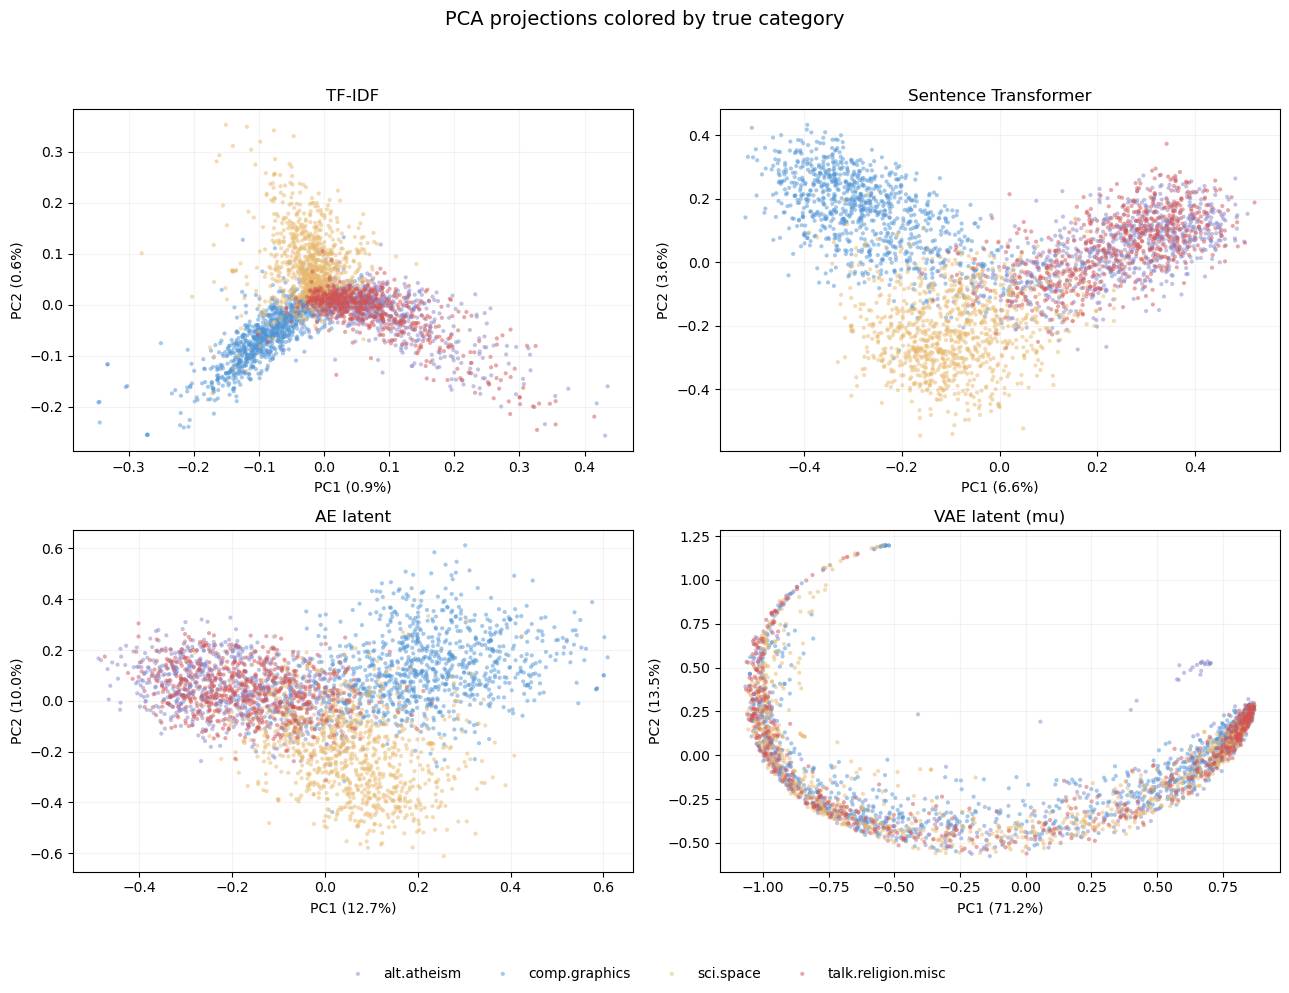

Figures saved to: /Users/cheeseowl/Desktop/科研/final_project/results/figures


In [31]:
import matplotlib.pyplot as plt

category_colors = {
    "alt.atheism": "#8887CB",
    "comp.graphics": "#5094D5",
    "sci.space": "#E8B86C",
    "talk.religion.misc": "#D15354",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, result) in zip(axes.flat, pca_results.items()):
    coordinates = result["coordinates"]
    variance_ratio = result["variance_ratio"]

    for label, category in label_to_category.items():
        mask = true_labels == label

        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=9,
            alpha=0.5,
            color=category_colors[category],
            label=category,
            edgecolors="none",
            rasterized=True,
        )

    ax.set_title(name)
    ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%})")
    ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%})")
    ax.grid(alpha=0.15)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "PCA projections colored by true category",
    fontsize=14,
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

figure_directory = Path("./results/figures")
figure_directory.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_directory / "representation_pca.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_directory / "representation_pca.pdf",
    bbox_inches="tight",
)

plt.show()

print("Figures saved to:", figure_directory.resolve())

### PCA 可视化观察

| 表示 | 前两维解释方差比例 |
|---|---:|
| TF-IDF | 约 1.45% |
| Sentence Transformer | 约 10.28% |
| AE latent | 约 22.70% |
| VAE latent (mu) | 约 84.67% |

Sentence Transformer：
图形学与航天文章形成较清楚的区域，
两个宗教相关类别仍然明显重叠。
这一观察与其较高的 ARI、NMI 一致。

AE：
保留了一定的图形学和航天结构，
但中心区域仍存在较多类别混合。

TF-IDF：
部分领域具有不同的分布方向，
但中心区域重叠明显。
前两个主成分仅解释约 1.45% 的方差，
二维图对完整表示空间的概括十分有限。

VAE：
投影呈明显弧形，但不同类别沿弧线混合。
前两个主成分解释约 84.67% 的方差，
表明其主要变化集中在少数线性方向上，
不代表这些变化对应真实类别。

结合词项数量诊断，
当前 VAE 的结构与其强烈反映保留词项数量的解释相容。

### 可视化结论

本次 PCA 图中，Sentence Transformer 的类别区域最清楚。
解释方差比例、几何结构与类别可分性是不同概念，
需要结合 ARI、NMI、Silhouette 和诊断结果共同判断。

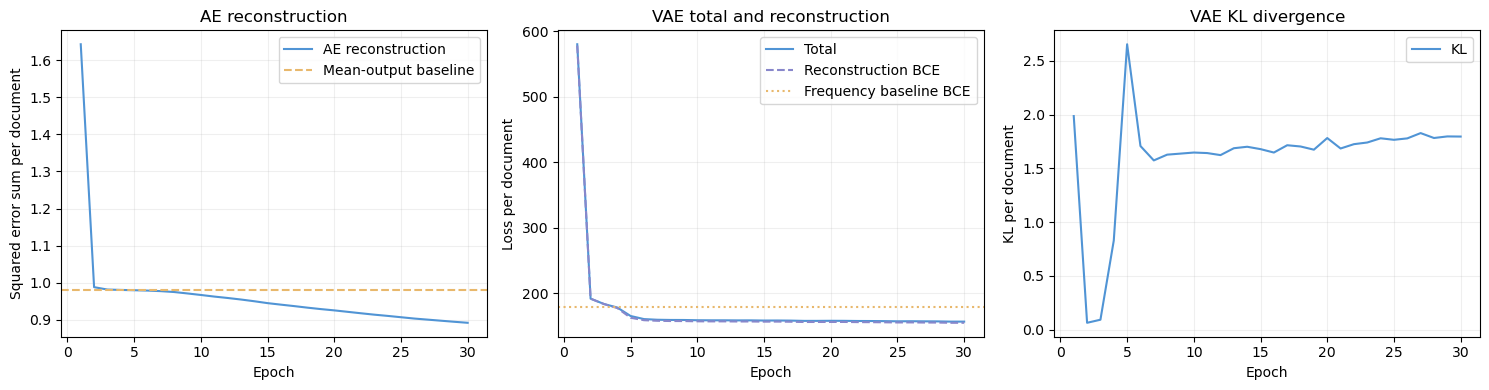

In [32]:
ae_epochs = [row["epoch"] for row in ae_history]
vae_epochs = [row["epoch"] for row in vae_history]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    ae_epochs,
    [row["train_loss"] for row in ae_history],
    color="#5094D5",
    label="AE reconstruction",
)
axes[0].axhline(
    mean_baseline_loss,
    color="#E8B86C",
    linestyle="--",
    label="Mean-output baseline",
)
axes[0].set_title("AE reconstruction")
axes[0].set_ylabel("Squared error sum per document")

axes[1].plot(
    vae_epochs,
    [row["train_total"] for row in vae_history],
    color="#5094D5",
    label="Total",
)
axes[1].plot(
    vae_epochs,
    [row["train_reconstruction"] for row in vae_history],
    color="#8887CB",
    linestyle="--",
    label="Reconstruction BCE",
)
axes[1].axhline(
    frequency_baseline_bce.item(),
    color="#E8B86C",
    linestyle=":",
    label="Frequency baseline BCE",
)
axes[1].set_title("VAE total and reconstruction")
axes[1].set_ylabel("Loss per document")

axes[2].plot(
    vae_epochs,
    [row["train_kl"] for row in vae_history],
    color="#5094D5",
    label="KL",
)
axes[2].set_title("VAE KL divergence")
axes[2].set_ylabel("KL per document")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()

fig.savefig(
    figure_directory / "text_model_training.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figure_directory / "text_model_training.pdf",
    bbox_inches="tight",
)

plt.show()

In [33]:
table_directory = Path("./results/tables")
table_directory.mkdir(parents=True, exist_ok=True)

tables_to_save = {
    "clustering_results.csv": pd.DataFrame(
        list(clustering_results.values())
    ),
    "pca_variance.csv": pca_summary_df,
    "ae_training_history.csv": pd.DataFrame(ae_history),
    "vae_training_history.csv": pd.DataFrame(vae_history),
    "lda_topics.csv": lda_topics_df,
    "vae_mu_count_correlations.csv": mu_correlation_df,
    "document_manifest.csv": clean_text_df[
        ["original_index", "label", "category"]
    ],
}

for filename, table in tables_to_save.items():
    table.to_csv(
        table_directory / filename,
        index=False,
        encoding="utf-8-sig",
    )

print("Tables saved to:", table_directory.resolve())
print("Figures saved to:", figure_directory.resolve())

Tables saved to: /Users/cheeseowl/Desktop/科研/final_project/results/tables
Figures saved to: /Users/cheeseowl/Desktop/科研/final_project/results/figures


## 7. 最终比较与讨论

### 1. 哪种表示的聚类结果最好？

在本次设置下，Sentence Transformer 的 ARI=0.5025、
NMI=0.5306，均为四种表示中最高。

按这两个指标排序：
Sentence Transformer > AE > TF-IDF > VAE。

### 2. 哪种表示的可视化最清楚？

本次 PCA 图中，Sentence Transformer 的类别区域最清楚。
图形学与航天文章形成较明显的区域，
两个宗教相关类别仍然重叠。

二维投影只反映部分信息，不能代替完整空间中的评价。

### 3. AE 是否学到了有用的表示？

本次 AE 将 5000 维 TF-IDF 压缩为 32 维，
ARI 从 0.1765 提高到 0.3193，
NMI 从 0.3602 提高到 0.3995。

这些结果支持其编码保留了部分有利于聚类的信息，
但表现仍低于预训练文本表示。

### 4. VAE 的表现与 AE 有什么不同？

VAE 的重建 BCE 优于固定的词项频率基线，
但 ARI、NMI 接近零。

其潜在表示与保留词项数量存在较强相关，
形成了几何分组明显、类别却混合的结构。

AE 与 VAE 同时存在输入表示、词表大小、
潜在维度和损失函数的差异，
不能将结果差异单独归因于模型结构。

### 5. 预训练语义表示为什么可能不同于 TF-IDF？

TF-IDF 根据当前语料的词项统计构造表示，
不直接利用词序和上下文。

Sentence Transformer 使用预训练模型编码文本，
可能受益于预训练中学到的语义关系。
本次实验结果与这一解释相容，但没有单独验证其因果作用。

### 6. 压缩文档可能丢失什么？

压缩可能丢失低频词、细节差异和区分类别的重要线索。
重建目标也可能优先保留整体统计特征，
而非我们关注的类别信息。

维度更低或重建误差更小，都不保证聚类更好。

### 7. 主题发现与文档聚类有什么联系？

两者都从未标注文本中探索潜在结构。
本次发现的航天、图像技术、宗教主题，
与部分文档簇的内容方向相关。

### 8. 两者有什么区别？

本实验的 K-means 为每篇文档分配一个簇。
LDA 学习主题的词语分布，并为每篇文档估计主题混合比例。

一个文档簇可能包含多个讨论主题，
一篇文档也可以同时涉及多个主题。

### 9. 如果再有一个月，会尝试什么？

- 使用多个随机种子，检查结论的稳定性。
- 加入独立保留文档，评价表示在新文档上的表现。
- 在相同输入表示与词表下比较 AE 和 VAE。
- 进一步检查并控制保留词项数量的影响。
- 使用明确的验证规则比较训练轮数、潜在维度与学习率。

### 本项目学到的主要经验

需要同时检查训练目标、外部评价、内部评价与实际文档。
VAE 的高 Silhouette、低 ARI/NMI 和词项数量诊断，
说明几何结构清楚并不等于语义类别清楚。

### 实验局限

- 仅使用一个随机种子。
- 在当前完整文档集合上学习表示并评价聚类，
  没有独立测试集，结论限定于当前语料。
- 不同方法的输入、维度及训练来源不同。
- Sentence Transformer 对长文本进行截断。
- 保留了特征过滤后成为全零输入的文档。

In [34]:
import json
import platform
import joblib
from importlib.metadata import version
from scipy.sparse import save_npz

model_directory = Path("./results/models")
model_directory.mkdir(parents=True, exist_ok=True)

neural_models = [
    (
        "text_ae", ae_model, X_tfidf.shape[1],
        AE_LATENT_DIM, AE_LEARNING_RATE, ae_history,
    ),
    (
        "text_vae", vae_model, X_bow.shape[1],
        VAE_LATENT_DIM, VAE_LEARNING_RATE, vae_history,
    ),
]

for name, network, input_dim, latent_dim, learning_rate, records in neural_models:
    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu().clone()
                for key, value in network.state_dict().items()
            },
            "input_dim": input_dim,
            "latent_dim": latent_dim,
            "hidden_dims": [512, 128],
            "learning_rate": learning_rate,
            "epochs": len(records),
            "batch_size": 128,
            "random_seed": RANDOM_SEED,
            "history": records,
        },
        model_directory / f"{name}.pt",
    )

joblib.dump(
    {
        "tfidf_vectorizer": tfidf_vectorizer,
        "bow_vectorizer": bow_vectorizer,
        "lda_count_vectorizer": lda_count_vectorizer,
        "kmeans_tfidf": kmeans_tfidf,
        "kmeans_embeddings": kmeans_embeddings,
        "kmeans_ae": kmeans_ae,
        "kmeans_vae": kmeans_vae,
        "lda_model": lda_model,
        "pca_models": {
            name: result["model"]
            for name, result in pca_results.items()
        },
    },
    model_directory / "sklearn_models.joblib",
    compress=3,
)

save_npz(feature_directory / "tfidf.npz", X_tfidf)
save_npz(feature_directory / "binary_bow.npz", X_bow_sparse)
save_npz(feature_directory / "lda_counts.npz", X_lda_counts)

np.savez_compressed(
    feature_directory / "document_outputs.npz",
    document_ids=document_ids,
    clusters_tfidf=clusters_tfidf,
    clusters_embeddings=clusters_embeddings,
    clusters_ae=clusters_ae,
    clusters_vae=clusters_vae,
    lda_document_topic=lda_document_topic,
)

packages = [
    "numpy", "pandas", "scipy", "scikit-learn",
    "torch", "sentence-transformers", "matplotlib",
    "threadpoolctl", "joblib",
]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

Path("requirements.txt").write_text(
    requirements_text,
    encoding="utf-8",
)

run_metadata = {
    "python": sys.version,
    "platform": platform.platform(),
    "random_seed": RANDOM_SEED,
    "documents": len(documents),
    "kmeans_parameters": kmeans_tfidf.get_params(),
    "silhouette_metric": "euclidean",
    "silhouette_sample_size": min(2000, len(documents)),
    "silhouette_random_seed": RANDOM_SEED,
    "sentence_transformer": MODEL_NAME,
    "maximum_sequence_length": embedding_model.max_seq_length,
    "ae_final_reconstruction_loss": final_ae_loss,
    "vae_final_metrics": vae_final_metrics,
    "scope": "Unsupervised learning and evaluation on the same corpus",
}

Path("./results/run_metadata.json").write_text(
    json.dumps(run_metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Models saved to:", model_directory.resolve())
print("Features saved to:", feature_directory.resolve())
print("Requirements saved to:", Path("requirements.txt").resolve())
print("Run metadata saved.")

Models saved to: /Users/cheeseowl/Desktop/科研/final_project/results/models
Features saved to: /Users/cheeseowl/Desktop/科研/final_project/results/features
Requirements saved to: /Users/cheeseowl/Desktop/科研/final_project/requirements.txt
Run metadata saved.
